# Activity 4: Philippine Bill Detection
Segment the bills from the paper background, separate touching bills, then classify each bill by its color.

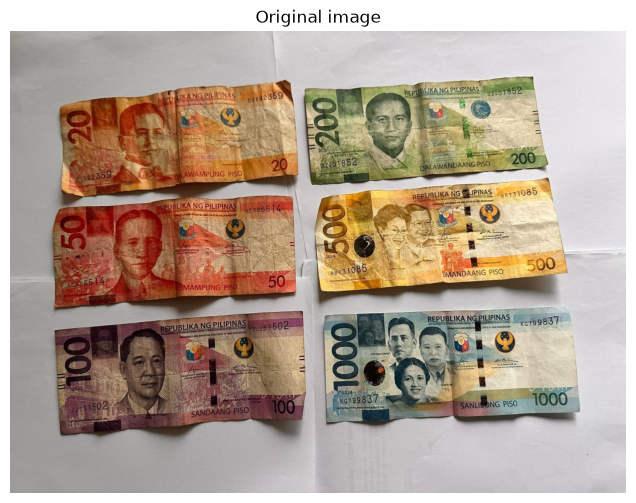

In [31]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from skimage.measure import label, regionprops
from skimage.feature import peak_local_max
from skimage.segmentation import watershed

image = cv2.imread('Images/bills.png')
if image is None:
    raise FileNotFoundError("Image not found.")

W = 1024
image = cv2.resize(image, (W, int(image.shape[0] * W / image.shape[1])))
image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

blur = cv2.GaussianBlur(image, (5, 5), 0)
hsv = cv2.cvtColor(blur, cv2.COLOR_BGR2HSV)
lab = cv2.cvtColor(blur, cv2.COLOR_BGR2LAB)

plt.figure(figsize=(8, 6))
plt.imshow(image_rgb)
plt.title("Original image")
plt.axis("off")
plt.show()

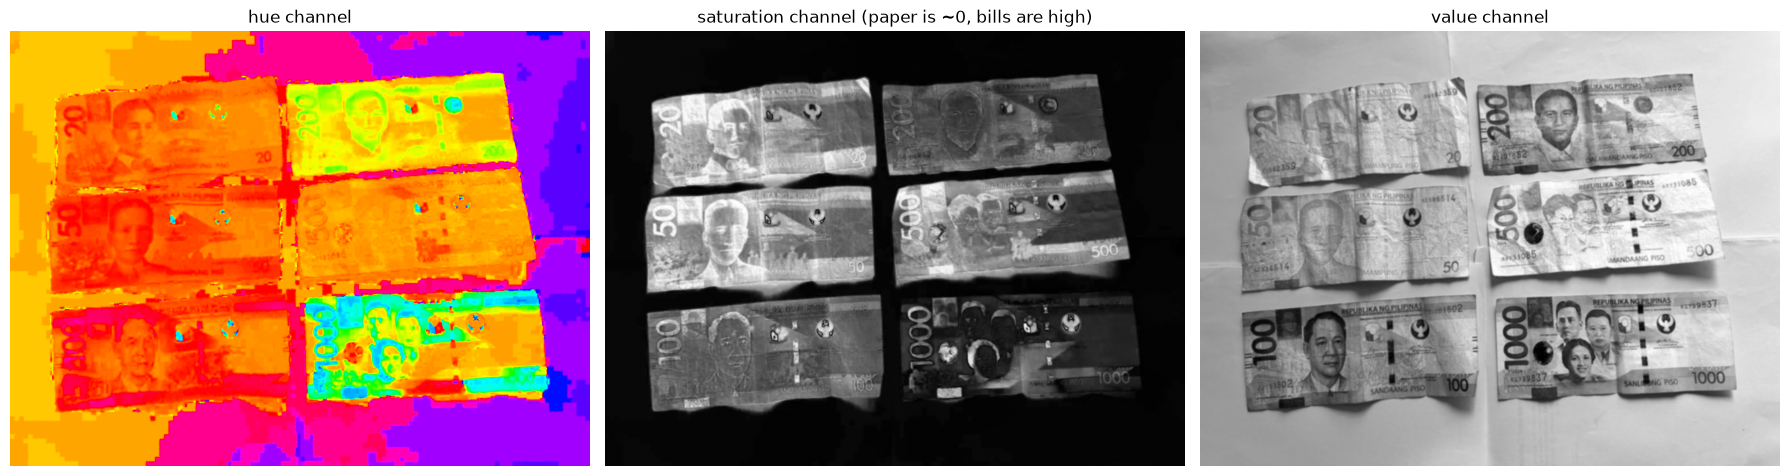

In [ ]:
hmat = hsv[:, :, 0]
smat = hsv[:, :, 1]
vmat = hsv[:, :, 2]

fig, axs = plt.subplots(1, 3, figsize=(18, 6))
axs[0].imshow(hmat, cmap='hsv')
axs[0].set_title("hue channel")
axs[0].axis("off")

axs[1].imshow(smat, cmap='gray')
axs[1].set_title("saturation channel (paper is ~0, bills are high)")
axs[1].axis("off")

axs[2].imshow(vmat, cmap='gray')
axs[2].set_title("value channel")
axs[2].axis("off")

plt.tight_layout()
plt.show()

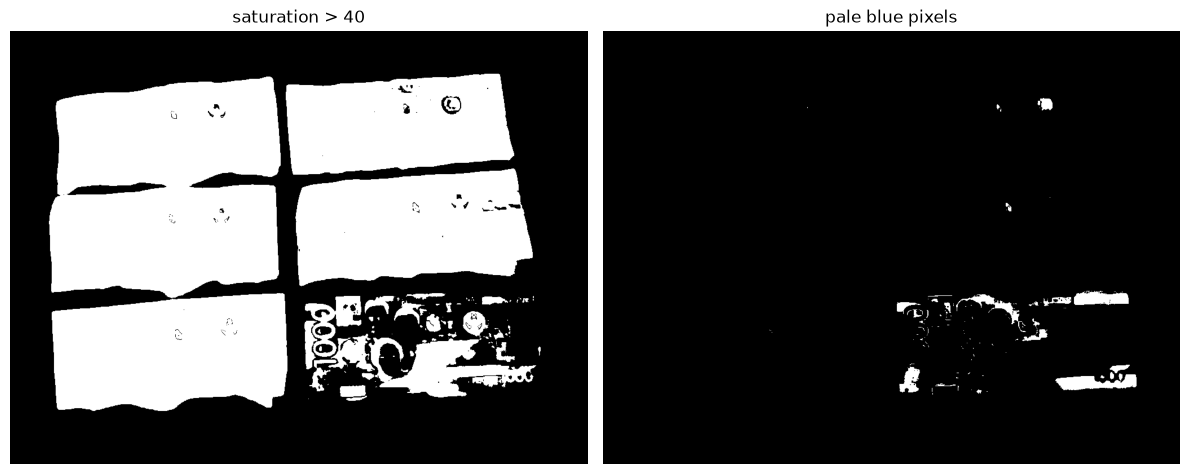

In [ ]:
sat_mask  = (smat > 40).astype(np.uint8) * 255
pale_blue = ((hmat > 80) & (hmat < 130) & (smat > 12) & (vmat > 90)).astype(np.uint8) * 255

fig, axs = plt.subplots(1, 2, figsize=(12, 6))
axs[0].imshow(sat_mask, cmap='gray')
axs[0].set_title("saturation > 40")
axs[0].axis("off")

axs[1].imshow(pale_blue, cmap='gray')
axs[1].set_title("pale blue pixels")
axs[1].axis("off")

plt.tight_layout()
plt.show()

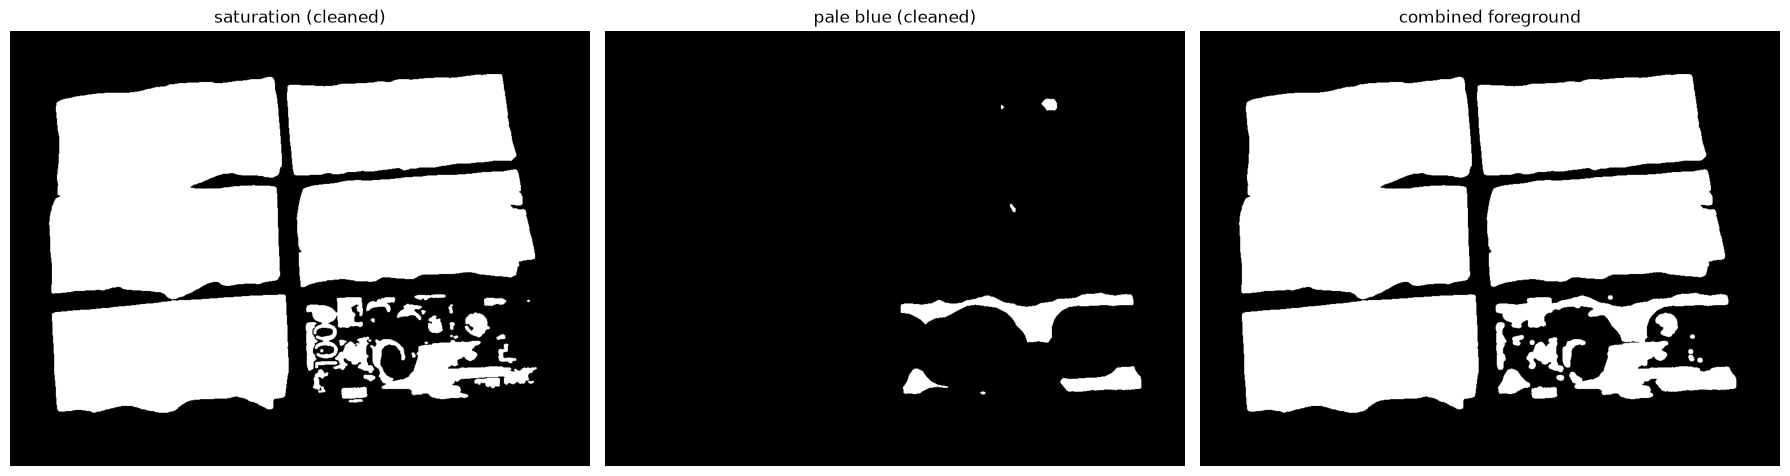

In [ ]:
def ellipse(k):
    return cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (k, k))

def fill_holes(mask):
    """Fill the inside of every outer contour."""
    contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    out = np.zeros_like(mask)
    cv2.drawContours(out, contours, -1, 255, -1)
    return out

sat_clean = fill_holes(cv2.morphologyEx(sat_mask, cv2.MORPH_OPEN, ellipse(5)))

pale_clean = cv2.morphologyEx(cv2.morphologyEx(pale_blue, cv2.MORPH_OPEN, ellipse(3)),
                              cv2.MORPH_CLOSE, ellipse(45), iterations=2)
pale_clean = fill_holes(pale_clean)

foreground = fill_holes(cv2.bitwise_or(sat_clean, pale_clean))
foreground = cv2.morphologyEx(foreground, cv2.MORPH_OPEN, ellipse(9))

fig, axs = plt.subplots(1, 3, figsize=(18, 6))
axs[0].imshow(sat_clean, cmap='gray')
axs[0].set_title("saturation (cleaned)")
axs[0].axis("off")

axs[1].imshow(pale_clean, cmap='gray')
axs[1].set_title("pale blue (cleaned)")
axs[1].axis("off")

axs[2].imshow(foreground, cmap='gray')
axs[2].set_title("combined foreground")
axs[2].axis("off")

plt.tight_layout()
plt.show()

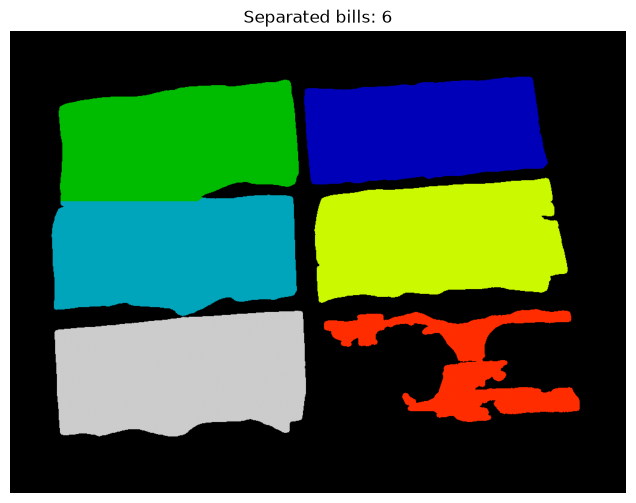

1 area = 60413.0
2 area = 70249.0
3 area = 67933.0
4 area = 70586.0
5 area = 27491.0
6 area = 75136.0


In [ ]:
label_image = label(foreground > 0)
regions = regionprops(label_image)

min_area = 0.01 * foreground.size                      # ignore tiny blobs
regions = [r for r in regions if r.area >= min_area]
median_area = np.median([r.area for r in regions])

bill_labels = np.zeros(foreground.shape, np.int32)     # one id per bill
next_id = 0
for r in regions:
    mask = (label_image == r.label)
    if r.area > 1.6 * median_area:
        dist = cv2.distanceTransform(mask.astype(np.uint8) * 255, cv2.DIST_L2, 5)
        dist = cv2.GaussianBlur(dist, (0, 0), 5)
        peaks = peak_local_max(dist, min_distance=70, threshold_abs=40,
                               labels=mask.astype(int), num_peaks=2)
        markers = np.zeros(foreground.shape, np.int32)
        for j, (y, x) in enumerate(peaks, 1):
            markers[y, x] = j
        markers = cv2.dilate(markers.astype(np.uint8), ellipse(9)).astype(np.int32)
        split = watershed(-dist, markers, mask=mask)
        for j in range(1, split.max() + 1):
            next_id += 1
            bill_labels[split == j] = next_id
    else:
        next_id += 1
        bill_labels[mask] = next_id

bills = regionprops(bill_labels)

plt.figure(figsize=(8, 6))
plt.imshow(bill_labels, cmap='nipy_spectral')
plt.title(f"Separated bills: {len(bills)}")
plt.axis("off")
plt.show()

for region in bills:
    print(region.label, "area =", region.area)

bill 1: a*=-5.9, b*=22.6 -> Green
bill 2: a*=25.5, b*=27.9 -> Red
bill 3: a*=18.3, b*=32.3 -> Orange
bill 4: a*=7.3, b*=34.8 -> Yellow
bill 5: a*=-2.3, b*=7.5 -> Blue
bill 6: a*=11.5, b*=11.1 -> Violet


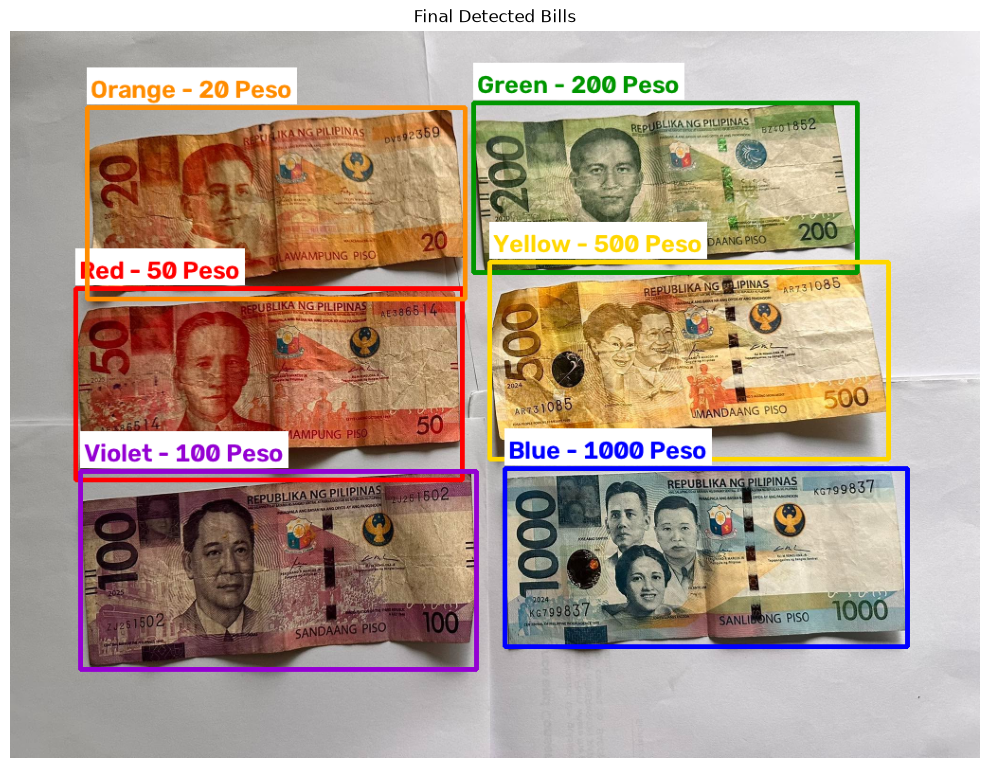

20 Peso (Orange): 1
50 Peso (Red): 1
100 Peso (Violet): 1
200 Peso (Green): 1
500 Peso (Yellow): 1
1000 Peso (Blue): 1

count: 6
Total value: P1870


In [ ]:
bill_colors = {
    'Orange': {'ab': (19, 31),  'box_color': (255, 140, 0), 'value': 20},
    'Red':    {'ab': (28, 26),  'box_color': (255, 0, 0),   'value': 50},
    'Violet': {'ab': (12, 8),   'box_color': (148, 0, 211), 'value': 100},
    'Green':  {'ab': (-8, 20),  'box_color': (0, 150, 0),   'value': 200},
    'Yellow': {'ab': (8, 36),   'box_color': (255, 215, 0), 'value': 500},
    'Blue':   {'ab': (-4, 5),   'box_color': (0, 0, 255),   'value': 1000},
}

def classify(region):
    mask = (bill_labels == region.label)
    a = lab[:, :, 1][mask].mean() - 128
    b = lab[:, :, 2][mask].mean() - 128
    name = min(bill_colors, key=lambda n: (a - bill_colors[n]['ab'][0]) ** 2
                                          + (b - bill_colors[n]['ab'][1]) ** 2)
    return name, a, b

output_img = image_rgb.copy()
counts = {name: 0 for name in bill_colors}

for region in bills:
    name, a, b = classify(region)
    print(f"bill {region.label}: a*={a:.1f}, b*={b:.1f} -> {name}")
    info = bill_colors[name]
    counts[name] += 1

    minr, minc, maxr, maxc = region.bbox
    cv2.rectangle(output_img, (minc, minr), (maxc, maxr), info['box_color'], 3)

    text = f"{name} - {info['value']} Peso"
    (tw, th), _ = cv2.getTextSize(text, cv2.FONT_HERSHEY_SIMPLEX, 0.9, 2)
    ty = max(minr - 10, th + 6)
    cv2.rectangle(output_img, (minc, ty - th - 8), (minc + tw + 8, ty + 6), (255, 255, 255), -1)
    cv2.putText(output_img, text, (minc + 4, ty), cv2.FONT_HERSHEY_SIMPLEX, 0.9, info['box_color'], 2)

fig, axs = plt.subplots(1, 1, figsize=(10, 8))
axs.imshow(output_img)
axs.set_title("Final Detected Bills")
axs.axis("off")
plt.tight_layout()
plt.show()

# Display counts and total value
total_count = sum(counts.values())
total_value = sum(counts[n] * bill_colors[n]['value'] for n in bill_colors)
for name, info in bill_colors.items():
    print(f"{info['value']} Peso ({name}): {counts[name]}")
print(f"\ncount: {total_count}")
print(f"Total value: P{total_value}")